In [ ]:

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Step 1: Load Dataset
df = pd.read_csv("car data.csv")
print(df.head())

# Step 2: Create Price Categories
df['Price_Category'] = pd.cut(
    df['Selling_Price'],
    bins=[-float('inf'), 3, 8, float('inf')],
    labels=['Low', 'Medium', 'High']
)

# Step 3: Select Input and Output
X = df[['Year', 'Kms_Driven', 'Present_Price']]
y = df['Price_Category']

# Step 4: Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Step 5: Scale Data
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Step 6: Train KNN Model
model = KNeighborsClassifier(n_neighbors=5)
model.fit(X_train, y_train)

# Step 7: Prediction
y_pred = model.predict(X_test)

# Step 8: Evaluation
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("Classification Report:")
print(classification_report(y_test, y_pred, zero_division=0))


In [1]:

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Step 1: Load Dataset
df = pd.read_csv("Iris.csv")
print(df.head())

# Step 2: Select Input and Output
X = df[['SepalLengthCm', 'SepalWidthCm',
        'PetalLengthCm', 'PetalWidthCm']]
y = df['Species']

# Step 3: Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Step 4: Scale Data
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Step 5: Train KNN Model
model = KNeighborsClassifier(n_neighbors=5)
model.fit(X_train, y_train)

# Step 6: Prediction
y_pred = model.predict(X_test)

# Step 7: Evaluation
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("Classification Report:")
print(classification_report(y_test, y_pred))


   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa
Accuracy: 1.0
Confusion Matrix:
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]
Classification Report:
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      1.00      1.00         9
 Iris-virginica       1.00      1.00      1.00        11

       accuracy                           1.00        30
      macro avg       1.00      1.00      1.00        30
   weighted avg       1.00      1.00      1.00        30



Original Dataset:
   gender race/ethnicity parental level of education         lunch  \
0  female        group B           bachelor's degree      standard   
1  female        group C                some college      standard   
2  female        group B             master's degree      standard   
3    male        group A          associate's degree  free/reduced   
4    male        group C                some college      standard   

  test preparation course  math score  reading score  writing score  
0                    none          72             72             74  
1               completed          69             90             88  
2                    none          90             95             93  
3                    none          47             57             44  
4                    none          76             78             75  

Clustered Dataset:
   gender race/ethnicity parental level of education         lunch  \
0  female        group B           bachelor's degre

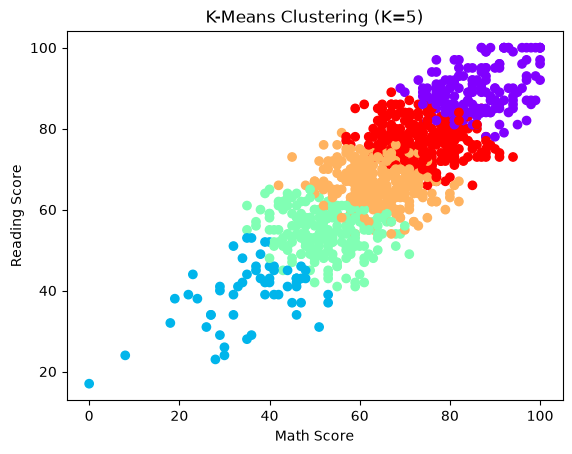


Silhouette Score: 0.3320345990111526
WCSS: 111309.68435889494


In [2]:
# Step 1: Import libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Step 2: Load dataset
df = pd.read_csv("StudentsPerformance.csv")

print("Original Dataset:")
print(df.head())

# Step 3: Select features
X = df[['math score', 'reading score', 'writing score']]

# Step 4: Apply K-Means with K = 5
model = KMeans(n_clusters=5, random_state=42, n_init=10)

df['Cluster'] = model.fit_predict(X)

print("\nClustered Dataset:")
print(df.head())

# Step 5: Visualize clusters
plt.scatter(df['math score'], df['reading score'],
            c=df['Cluster'], cmap='rainbow')

plt.xlabel("Math Score")
plt.ylabel("Reading Score")
plt.title("K-Means Clustering (K=5)")
plt.show()

# Step 6: Evaluation
score = silhouette_score(X, df['Cluster'])

print("\nSilhouette Score:", score)
print("WCSS:", model.inertia_)

In [ ]:
# Step 1: Import libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Step 2: Load dataset
df = pd.read_csv("Mall_Customers.csv")

print("Dataset:")
print(df.head())

# Step 3: Select features
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

# Step 4: Apply Elbow Method
wcss = []

for i in range(1, 11):
    km = KMeans(n_clusters=i, random_state=42, n_init=10)
    km.fit(X)
    wcss.append(km.inertia_)

# Step 5: Plot Elbow Graph
plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()

# Step 6: Apply K-Means
model = KMeans(n_clusters=5, random_state=42, n_init=10)
df['Cluster'] = model.fit_predict(X)

print("\nClustered Dataset:")
print(df.head())

# Step 7: Visualize Clusters
plt.scatter(X.iloc[:, 0], X.iloc[:, 1],
            c=df['Cluster'], cmap='rainbow')

# Plot Centroids
plt.scatter(model.cluster_centers_[:, 0],
            model.cluster_centers_[:, 1],
            color='black', marker='X', s=200,
            label='Centroids')

plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.title("K-Means Customer Clustering")
plt.legend()
plt.show()

# Step 8: Evaluation
from sklearn.metrics import silhouette_score

score = silhouette_score(X, df['Cluster'])
print("Silhouette Score:", score)